# 03 — Quasi-experiment across course presentations

The focal comparison is BBB 2013B (February) versus 2014J (October). These are
observational cohorts. Presentation changes coincide with differences in season,
calendar year, course length and potentially assessments and student mix.
Covariate adjustment addresses measured composition. The estimates describe
associations, and causal identification would require a stronger design.

**Primary outcome:** Pass or Distinction per module-presentation enrollment.
Every enrollment in the selected presentations enters the denominator, including
Fail and Withdrawn. **Secondary outcome:** mean recorded assessment score per
enrollment with at least one nonmissing score.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

SEED = 42
RAW = Path('../data/raw')
ASSETS = Path('../assets')
ASSETS.mkdir(exist_ok=True)
KEYS = ['id_student', 'code_module', 'code_presentation']
FOCAL = ('BBB', '2013B', '2014J')

sns.set_theme(style='whitegrid')
students = pd.read_csv(RAW / 'studentInfo.csv')
assert not students.duplicated(KEYS).any()
students['completed'] = students['final_result'].isin(['Pass', 'Distinction']).astype(int)
students['imd_band'] = students['imd_band'].fillna('Missing')

def p_text(p_value):
    return '<0.0001' if p_value < 0.0001 else f'{p_value:.4f}'

def select_pair(module, b, j):
    pair = students.loc[
        students['code_module'].eq(module) & students['code_presentation'].isin([b, j])
    ].copy()
    pair['j_presentation'] = pair['code_presentation'].eq(j).astype(int)
    return pair

focal = select_pair(*FOCAL)

## Primary outcome — completion among all enrollments

Each eligible module contributes its earliest B and latest J presentation, a
fixed rule based on presentation metadata. The contrast can span different
calendar years. Each row reports the raw rate and difference, and a logistic
regression adjusted for age band, education, IMD, gender as recorded in OULAD,
disability, studied credits and region. Missing IMD is a separate category.

Adjusted rates average predicted completion under each presentation indicator
over the pooled observed covariates for that module. Wald intervals and p-values
use student-clustered covariance and the delta method for the average difference.
The B/J rows are exploratory and p-values are nominal. They share the same
dataset and some students across modules.

In [2]:
presentations = pd.read_csv(RAW / 'courses.csv')
presentations['season'] = presentations['code_presentation'].str[-1]
pairs = (
    presentations.groupby(['code_module', 'season'])['code_presentation']
    .agg(first='min', last='max').unstack('season')
)
eligible = pairs.dropna(subset=[('first', 'B'), ('last', 'J')])
print('Modules without a B/J pair:', ', '.join(pairs.index.difference(eligible.index)))

COVARIATES = (
    'C(age_band) + C(highest_education) + C(imd_band) + C(gender) + '
    'C(disability) + studied_credits + C(region)'
)

def completion_contrast(module, b, j):
    pair = select_pair(module, b, j)
    assert not pair[['age_band', 'highest_education', 'imd_band', 'gender',
                     'disability', 'studied_credits', 'region']].isna().any().any()
    counts = pair.groupby('j_presentation')['completed'].agg(['size', 'sum', 'mean'])
    result = {'module': module, 'B': b, 'J': j}
    for arm, label in [(0, 'B'), (1, 'J')]:
        result[f'{label} completed'] = f'{counts.loc[arm, "sum"]:.0f}/{counts.loc[arm, "size"]:.0f}'
        result[f'{label} rate (%)'] = 100 * counts.loc[arm, 'mean']

    for label, terms in [('Raw', ''), ('Adjusted', ' + ' + COVARIATES)]:
        fit = smf.glm(
            'completed ~ j_presentation' + terms, pair, family=sm.families.Binomial()
        ).fit(cov_type='cluster', cov_kwds={'groups': pair['id_student']})
        assert fit.converged and fit.nobs == len(pair)
        contrast = fit.get_margeff(dummy=True, at='overall').summary_frame().loc['j_presentation']
        difference = contrast['dy/dx']
        se = contrast['Std. Err.']
        result[f'{label} J−B (pp)'] = 100 * difference
        result[f'{label} 95% CI (pp)'] = f'[{100 * (difference - 1.96 * se):+.1f}, {100 * (difference + 1.96 * se):+.1f}]'
        result[f'{label} p'] = p_text(2 * stats.norm.sf(abs(difference / se)))
    result['Adjusted lower CI'] = 100 * (difference - 1.96 * se)
    return result

completion = pd.DataFrame([
    completion_contrast(module, row[('first', 'B')], row[('last', 'J')])
    for module, row in eligible.iterrows()
]).set_index('module')
adjusted_lower = completion.pop('Adjusted lower CI')
display(completion.round(2))

Modules without a B/J pair: AAA


,B,J,B completed,B rate (%),J completed,J rate (%),Raw J−B (pp),Raw 95% CI (pp),Raw p,Adjusted J−B (pp),Adjusted 95% CI (pp),Adjusted p
module,,,,,,,,,,,,
BBB,2013B,2014J,803/1767,45.44,1152/2292,50.26,4.82,"[+1.7, +7.9]",0.0023,2.55,"[-0.5, +5.6]",0.1001
CCC,2014B,2014J,663/1936,34.25,1015/2498,40.63,6.39,"[+3.5, +9.2]",<0.0001,6.24,"[+3.5, +9.0]",<0.0001
DDD,2013B,2014J,510/1303,39.14,792/1803,43.93,4.79,"[+1.3, +8.3]",0.0072,5.23,"[+1.9, +8.6]",0.0023
EEE,2014B,2014J,357/694,51.44,684/1188,57.58,6.13,"[+1.5, +10.8]",0.0093,6.97,"[+2.4, +11.6]",0.0030
FFF,2013B,2014J,782/1614,48.45,1117/2365,47.23,-1.22,"[-4.4, +1.9]",0.4484,0.16,"[-2.9, +3.2]",0.9184
GGG,2014B,2014J,478/833,57.38,444/749,59.28,1.90,"[-3.0, +6.8]",0.4460,3.03,"[-2.1, +8.1]",0.2443


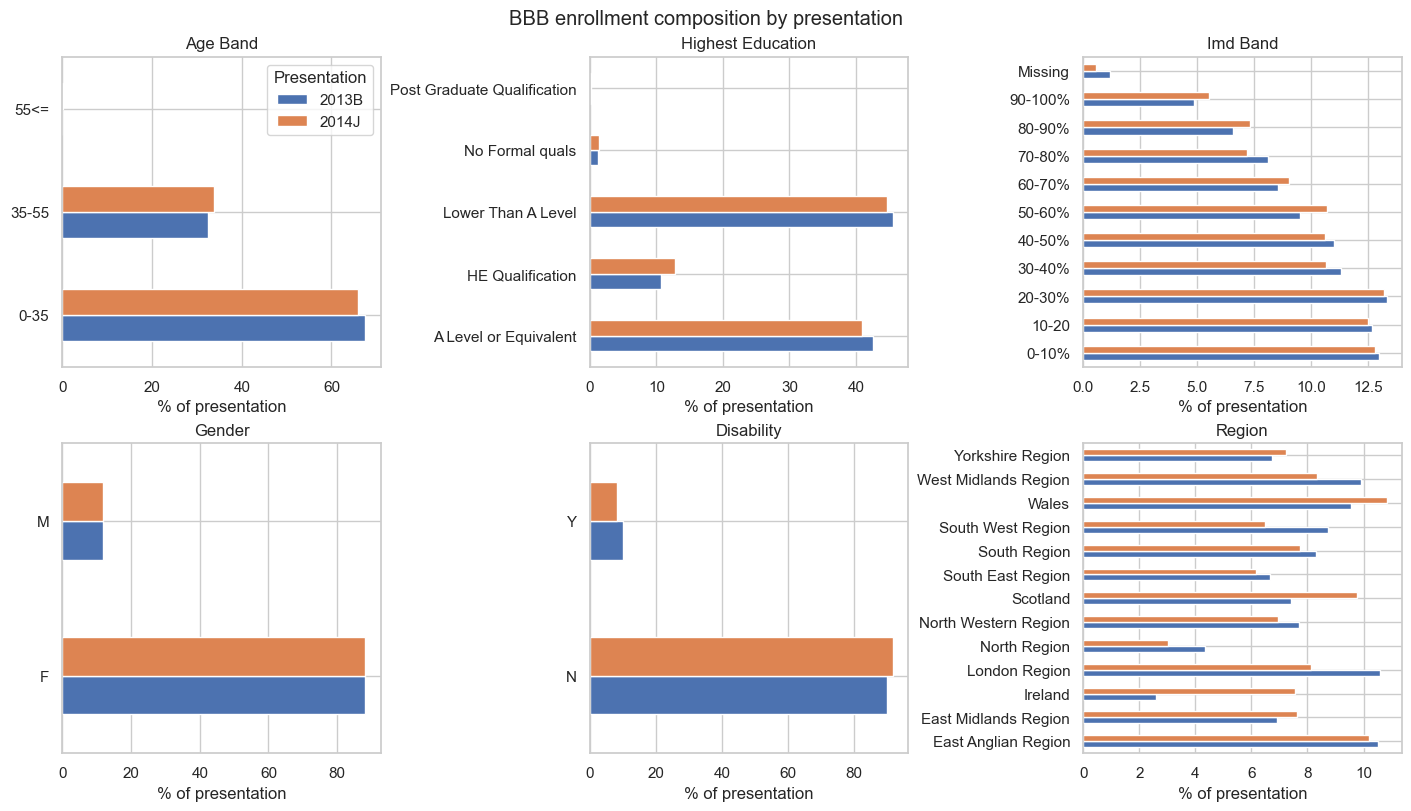

In [3]:
balance_cols = ['age_band', 'highest_education', 'imd_band', 'gender', 'disability', 'region']
fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout='constrained')
for field, ax in zip(balance_cols, axes.flat):
    shares = pd.crosstab(focal[field], focal['code_presentation'], normalize='columns')
    shares.mul(100).plot.barh(ax=ax, legend=False)
    ax.set(title=field.replace('_', ' ').title(), ylabel='', xlabel='% of presentation')
axes[0, 0].legend(title='Presentation')
fig.suptitle('BBB enrollment composition by presentation')
fig.savefig(ASSETS / '03_group_balance.png', dpi=125, bbox_inches='tight')
plt.show()

## Secondary outcome — recorded assessment scores

Assessment IDs are joined to their own module and presentation. Each scored
enrollment contributes its mean across available assessment scores, including
recorded banked scores. Enrollment coverage is shown by presentation. Restricting
the outcome to scored enrollments creates selection (survivorship) bias. Tasks,
marking, and the mix of banked scores can also differ by presentation.

Welch's test compares means. Mann–Whitney U compares score ranks. Both are
conventional unpaired tests and treat enrollments as independent. The bootstrap
resamples student IDs across both presentations together, preserving repeated
students in the interval for the mean difference.

,enrolled,scored,mean,median,sd,coverage (%)
code_presentation,,,,,,
2013B,1767,1366,77.17,79.5,11.96,77.31
2014J,2292,1792,64.31,67.6,21.95,78.18


Welch t = -21.051, p <0.0001
Mann–Whitney U (J vs B) = 724,852, p <0.0001
Score difference (J − B): -12.86 points. Cohen’s d: -0.703.
Student IDs with a score in both presentations: 10


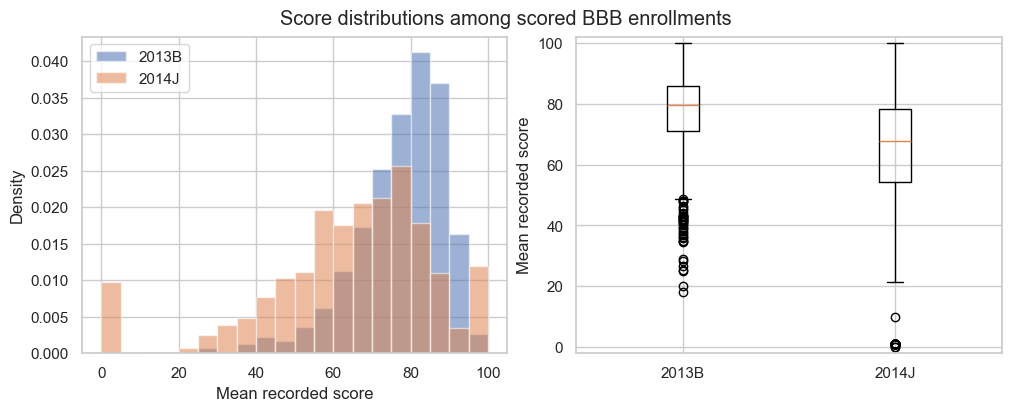

In [4]:
assessments = pd.read_csv(RAW / 'assessments.csv', usecols=['id_assessment', *KEYS[1:]])
submissions = pd.read_csv(RAW / 'studentAssessment.csv', usecols=['id_assessment', 'id_student', 'score'])
student_scores = (
    submissions.dropna(subset=['score'])
    .merge(assessments, on='id_assessment', validate='many_to_one')
    .groupby(KEYS, as_index=False)['score'].mean()
)
scored = focal.merge(student_scores, on=KEYS, how='left', validate='one_to_one')
score_summary = scored.groupby('code_presentation')['score'].agg(
    enrolled='size', scored='count', mean='mean', median='median', sd='std'
)
score_summary['coverage (%)'] = 100 * score_summary['scored'] / score_summary['enrolled']
display(score_summary.round(2))

_, b, j = FOCAL
scores = scored.pivot(index='id_student', columns='code_presentation', values='score')[[b, j]].dropna(how='all')
left = scores[b].dropna().to_numpy()
right = scores[j].dropna().to_numpy()
welch = stats.ttest_ind(right, left, equal_var=False)
mann_whitney = stats.mannwhitneyu(right, left, alternative='two-sided')
delta = right.mean() - left.mean()
pooled_sd = np.sqrt(((len(left) - 1) * left.var(ddof=1) + (len(right) - 1) * right.var(ddof=1))
                    / (len(left) + len(right) - 2))
print(f'Welch t = {welch.statistic:.3f}, p {p_text(welch.pvalue)}')
print(f'Mann–Whitney U (J vs B) = {mann_whitney.statistic:,.0f}, p {p_text(mann_whitney.pvalue)}')
print(f'Score difference (J − B): {delta:+.2f} points. Cohen’s d: {delta / pooled_sd:+.3f}.')
print(f'Student IDs with a score in both presentations: {scores.notna().all(axis=1).sum():,}')

fig, (hist_ax, box_ax) = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for label in (b, j):
    hist_ax.hist(scores[label].dropna(), bins=np.arange(0, 105, 5), alpha=0.55,
                 density=True, label=label)
hist_ax.set(xlabel='Mean recorded score', ylabel='Density')
hist_ax.legend()
box_ax.boxplot([left, right], tick_labels=[b, j])
box_ax.set(ylabel='Mean recorded score', ylim=(-2, 102))
fig.suptitle('Score distributions among scored BBB enrollments')
fig.savefig(ASSETS / '03_score_distribution.png', dpi=125, bbox_inches='tight')
plt.show()

Student-cluster bootstrap (10,000 draws), 95% CI: [-14.07, -11.68] points.


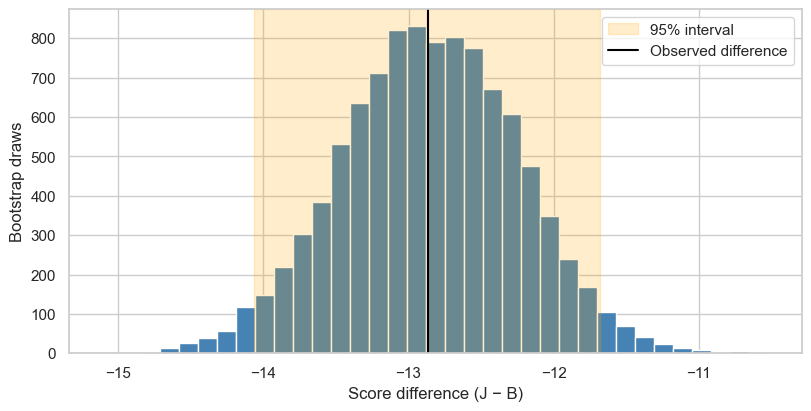

In [5]:
rng = np.random.default_rng(SEED)
bootstrap_deltas = []
for _ in range(100):
    sampled = rng.integers(len(scores), size=(100, len(scores)))
    boot_means = np.nanmean(scores.to_numpy()[sampled], axis=1)
    bootstrap_deltas.extend(boot_means[:, 1] - boot_means[:, 0])

low, high = np.quantile(bootstrap_deltas, [0.025, 0.975])
print(f'Student-cluster bootstrap ({len(bootstrap_deltas):,} draws), 95% CI: [{low:+.2f}, {high:+.2f}] points.')
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
ax.hist(bootstrap_deltas, bins=35, color='steelblue')
ax.axvspan(low, high, color='orange', alpha=0.2, label='95% interval')
ax.axvline(delta, color='black', label='Observed difference')
ax.set(xlabel='Score difference (J − B)', ylabel='Bootstrap draws')
ax.legend()
fig.savefig(ASSETS / '03_bootstrap_ci.png', dpi=125, bbox_inches='tight')
plt.show()

## Sample size for a future randomized study

Illustrative planning assumes independent observations, equal assignment and
a baseline equal to the earlier BBB completion rate. The plot does not account
for clustering or multiple outcomes.

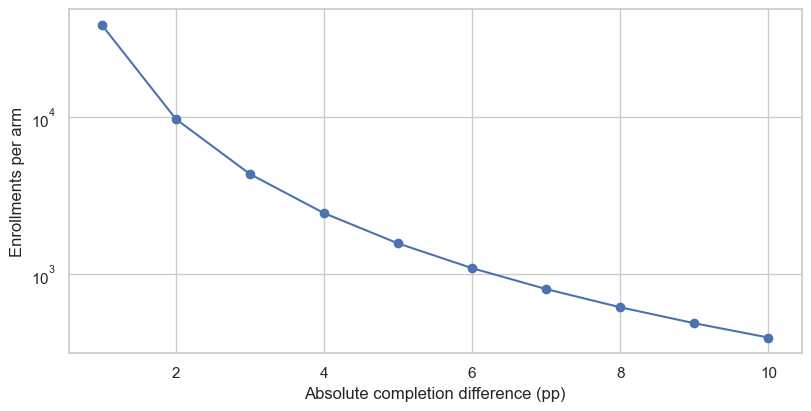

Illustrative sample per arm for a 5 pp difference: 1,566.


In [6]:
baseline = focal.loc[focal['j_presentation'].eq(0), 'completed'].mean()
changes = np.arange(1, 11)
samples = [
    np.ceil(NormalIndPower().solve_power(
        proportion_effectsize(baseline + change / 100, baseline),
        power=0.8, alpha=0.05, ratio=1,
    ))
    for change in changes
]
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
ax.plot(changes, samples, marker='o')
ax.set(xlabel='Absolute completion difference (pp)', ylabel='Enrollments per arm', yscale='log')
fig.savefig(ASSETS / '03_power_analysis.png', dpi=125, bbox_inches='tight')
plt.show()
print(f'Illustrative sample per arm for a 5 pp difference: {samples[4]:,.0f}.')

## Interpretation

The primary estimate describes how completion rates differ between presentations
after accounting for measured enrollment characteristics. The secondary score
contrast answers a different question about the subset with recorded scores.
Both arise from a quasi-experiment with uncontrolled presentation differences.

In [7]:
bbb = completion.loc['BBB']
adjusted = completion['Adjusted J−B (pp)']
print(f"BBB completion: {bbb['B rate (%)']:.1f}% in {b}, {bbb['J rate (%)']:.1f}% in {j}.")
for label in ['Raw', 'Adjusted']:
    print(f"{label} J − B: {bbb[f'{label} J−B (pp)']:+.1f} pp "
          f"(95% CI {bbb[f'{label} 95% CI (pp)']}, p {bbb[f'{label} p']}).")
print(f'Adjusted B/J differences range from {adjusted.min():+.1f} to {adjusted.max():+.1f} pp.')
print(f'Positive adjusted estimates: {(adjusted > 0).sum()} of {len(adjusted)} modules.')
print('Adjusted 95% intervals entirely above zero:', ', '.join(adjusted_lower[adjusted_lower > 0].index))
print('The direction recurs across the eligible modules, with varying magnitudes and precision.')
print(f'Mean recorded score among scored enrollments: {left.mean():.1f} in {b}, '
      f'{right.mean():.1f} in {j}.')

BBB completion: 45.4% in 2013B, 50.3% in 2014J.
Raw J − B: +4.8 pp (95% CI [+1.7, +7.9], p 0.0023).
Adjusted J − B: +2.6 pp (95% CI [-0.5, +5.6], p 0.1001).
Adjusted B/J differences range from +0.2 to +7.0 pp.
Positive adjusted estimates: 6 of 6 modules.
Adjusted 95% intervals entirely above zero: CCC, DDD, EEE
The direction recurs across the eligible modules, with varying magnitudes and precision.
Mean recorded score among scored enrollments: 77.2 in 2013B, 64.3 in 2014J.
